# 04 — Leaf image analysis with colour segmentation

## Goal and honest scope
Find a visible leaf, mark selected colour changes, calculate the marked-area percentage and display
an overlay. This is an explainable image-processing exercise, not a trained disease classifier.
It does not generate a diagnostic confidence score or a treatment prescription.

## Image concepts
A colour image is an array of height × width × 3 values. In RGB, the channels are red, green and blue.
HSV separates hue (colour), saturation (colour strength) and value (brightness). OpenCV's 8-bit HSV
hue range is 0–179; saturation and value range from 0–255. A binary mask stores 255 for included
pixels and 0 for excluded pixels. A contour describes a connected region's boundary.

## Processing sequence
1. Correct orientation, convert to RGB and resize while preserving aspect ratio.
2. Convert RGB to HSV and check that visible green tissue exists.
3. Find the largest coloured region and fill its outline as a leaf mask.
4. Select brown/rust, yellow and dark pixels within that mask.
5. Remove tiny specks with morphological opening.
6. Divide marked pixels by leaf pixels and blend red only over marked pixels.

The thresholds are heuristic design choices documented in `src/vision.py`. The included samples are
drawings from the source project. Their filenames are illustrative labels, not ground-truth photographic evidence.

## Environment and imports

**What we do:** Locate the project and import the libraries used in this notebook.

**Why we do it:** Relative paths let this project work after it is moved or cloned. pandas handles tables, NumPy handles arrays, and Matplotlib draws graphs. The src package contains shared, readable code.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open this notebook from the project folder or its notebooks folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.data import SPECS, load_data
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
print("Project:", ROOT.name)

Project: agrisense-college-mini


**Read the output:** The printed folder should be agrisense-college-mini. In VS Code select the project's .venv Python environment as the notebook kernel. Run cells from top to bottom.

## Open and inspect a sample

**What we do:** Read the tomato illustration and display its shape and pixels.

**Why we do it:** Looking at the actual image is necessary before reasoning about segmentation. The image is RGB, which avoids confusing OpenCV's common BGR input convention.

Shape (height, width, channels): (400, 400, 3)
Data type: uint8 Value range: 20 245


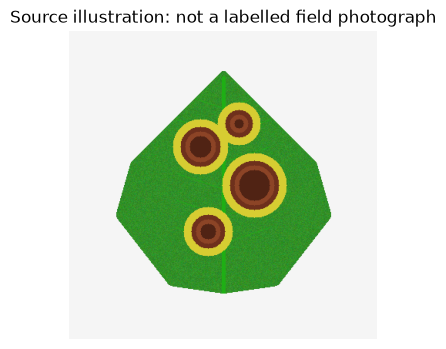

In [2]:
from PIL import Image
from src.vision import analyze_leaf, SAMPLE_CROPS
picture = Image.open(ROOT / "samples" / "tomato_early_blight.png").convert("RGB")
array = np.asarray(picture)
print("Shape (height, width, channels):", array.shape)
print("Data type:", array.dtype, "Value range:", array.min(), array.max())
plt.imshow(array)
plt.axis("off")
plt.title("Source illustration: not a labelled field photograph")
plt.show()

**Read the output:** There are three channels per pixel. A light background helps the chosen colour-based approach, but a cluttered scene can violate this assumption.

## Examine the HSV channels

**What we do:** Convert RGB to HSV and display the hue, saturation and brightness channels.

**Why we do it:** Separating colour from brightness makes simple threshold rules easier to explain.

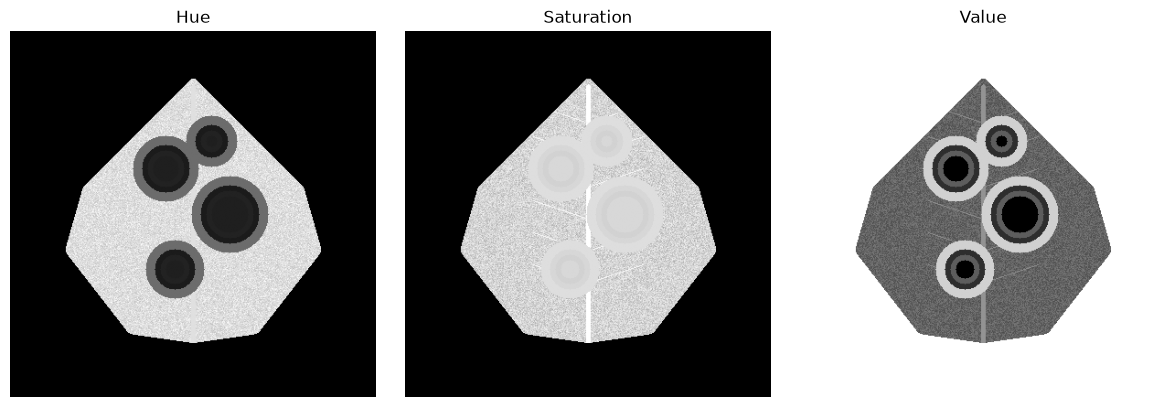

In [3]:
import cv2
hsv = cv2.cvtColor(array, cv2.COLOR_RGB2HSV)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for index, label in enumerate(["Hue", "Saturation", "Value"]):
    axes[index].imshow(hsv[:, :, index], cmap="gray")
    axes[index].set_title(label)
    axes[index].axis("off")
plt.tight_layout()
plt.show()

**Read the output:** The channels encode different aspects of the same image. Thresholds can still fail under shadows, unusual lighting, yellow leaves, coloured backgrounds or entirely dead leaves.

## Generate masks and an overlay

**What we do:** Run the deterministic algorithm and display the original, leaf mask, marked mask and overlay.

**Why we do it:** Showing intermediate masks makes the result inspectable. Filling the leaf boundary preserves dark internal patches; opening removes tiny marked specks. Unmarked pixels remain unchanged.

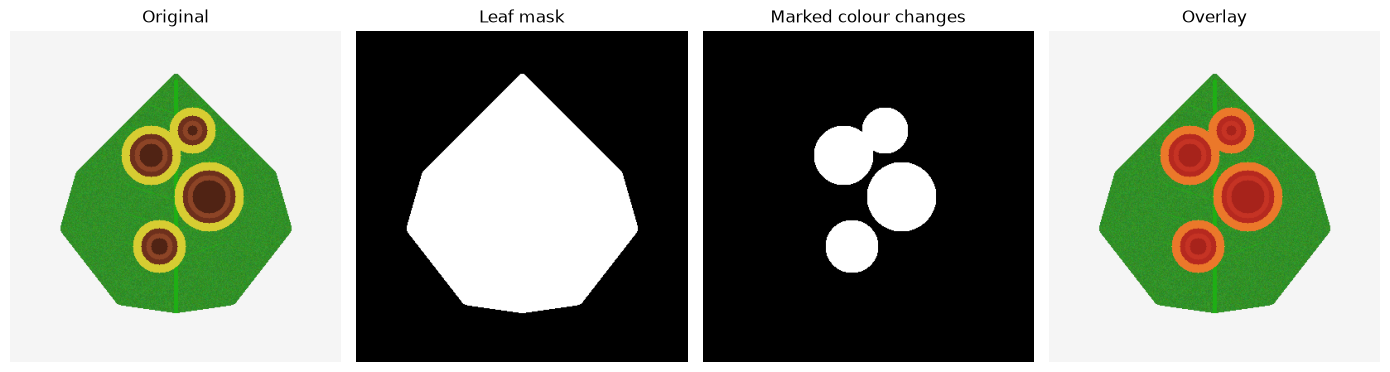

In [4]:
result = analyze_leaf(picture, crop="Tomato")
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, name, title in zip(
    axes, ["original", "leaf_mask", "affected_mask", "overlay"],
    ["Original", "Leaf mask", "Marked colour changes", "Overlay"]
):
    ax.imshow(result[name], cmap="gray" if "mask" in name else None)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Read the output:** White mask pixels are included. The marked mask must stay inside the leaf mask. A visually sensible overlay shows agreement with this illustration, not validated disease-recognition ability.

## Calculate affected-area percentage

**What we do:** Count marked and leaf pixels, then apply the ratio formula.

**Why we do it:** Using leaf area as the denominator avoids diluting the estimate with background pixels.

In [5]:
manual_percentage = result["affected_pixels"] / result["leaf_pixels"] * 100
display(pd.Series({
    "Leaf pixels": result["leaf_pixels"],
    "Marked pixels": result["affected_pixels"],
    "Marked percentage": manual_percentage,
    "Severity band": result["severity_band"],
    "Connected regions": result["regions"],
    "Illustrative match": result["illustrative_match"],
}, name="Image result"))
print("Ratio matches algorithm:", np.isclose(manual_percentage, result["affected_percent"]))
print("Marked pixels outside leaf:", np.count_nonzero((result["affected_mask"] > 0) & (result["leaf_mask"] == 0)))

Leaf pixels                                52615
Marked pixels                              15127
Marked percentage                      28.750356
Severity band                               High
Connected regions                              3
Illustrative match    Early-blight-like spotting
Name: Image result, dtype: object

Ratio matches algorithm: True
Marked pixels outside leaf: 0


**Read the output:** The band thresholds are educational: below 2.5% low colour change, below 10% mild, up to 25% moderate, above 25% high. These are not validated clinical/pathology severity categories. Connected regions are colour blobs, not necessarily individual lesions.

## Compare every included sample

**What we do:** Process all five illustrations with explicit crop hints and compare marked percentages.

**Why we do it:** A reproducible sample table is more informative than one selected image. The crop hint controls the descriptive example; it does not identify the crop from pixels.

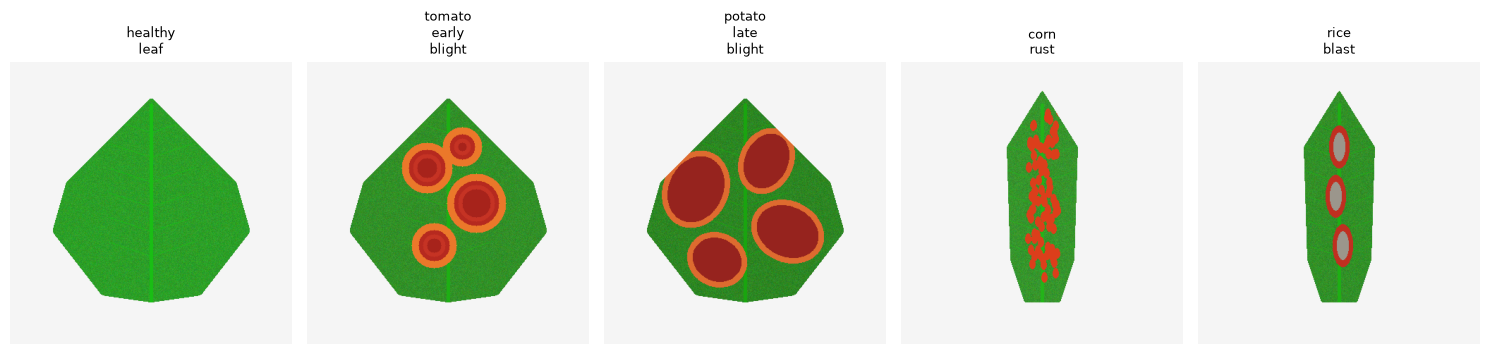

,Sample,Crop hint,Marked area (%),Band
0,healthy_leaf.png,Unspecified,0.00,Low colour change
1,tomato_early_blight.png,Tomato,28.75,High
2,potato_late_blight.png,Potato,50.18,High
3,corn_rust.png,Maize,26.49,High
4,rice_blast.png,Rice,10.67,Moderate


In [6]:
rows = []
fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for ax, (filename, crop_hint) in zip(axes, SAMPLE_CROPS.items()):
    with Image.open(ROOT / "samples" / filename) as sample:
        output = analyze_leaf(sample, crop_hint)
    rows.append({
        "Sample": filename, "Crop hint": crop_hint,
        "Marked area (%)": round(output["affected_percent"], 2),
        "Band": output["severity_band"],
    })
    ax.imshow(output["overlay"])
    ax.set_title(filename.replace("_", "\n").replace(".png", ""), fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows))

**Read the output:** The healthy illustration should have little marked area, while spotted samples should have more. Differences reflect colour rules and drawing design. This table cannot measure disease-classification accuracy.

## Test repeatability and reject an empty image

**What we do:** Run the same input twice and try a plain white image.

**Why we do it:** A deterministic algorithm should return the same result for the same input. A missing leaf should produce an explanation instead of inventing a leaf boundary or diagnosis.

In [7]:
repeated = analyze_leaf(picture, "Tomato")
print("Same percentage:", repeated["affected_percent"] == result["affected_percent"])
print("Same mask:", np.array_equal(repeated["affected_mask"], result["affected_mask"]))
unchanged = result["affected_mask"] == 0
print("Unmarked pixels preserved:", np.array_equal(result["original"][unchanged], result["overlay"][unchanged]))
try:
    analyze_leaf(Image.new("RGB", (200, 200), "white"))
except ValueError as error:
    print("Expected rejection:", error)

Same percentage: True
Same mask: True
Unmarked pixels preserved: True
Expected rejection: No clear green leaf region found. Use a leaf on a plain light background.


**Read the output:** The repeatability checks should be True, and the blank image should be rejected. The reference project used random confidence percentages; this project deliberately has no such output.

## Application connection
The interface accepts one of the included illustrations or an uploaded PNG/JPEG. It offers an explicit
crop hint and displays masks, marked area, an overlay and an illustrative comparison. It does not
automatically identify a causal pathogen. Real treatment decisions need an actual diagnosis.

## Known failure cases
Shadows can look like dark patches; yellowing may be normal ageing or stress; a colourful background
can become the largest contour. Multiple leaves, very small leaves and completely brown leaves may be
rejected or segmented incorrectly. Resizing also changes small details. An apparently clear match can be wrong.

## Future extension
Collect appropriately licensed, expert-labelled leaf photographs. Split by plant/location rather than
near-duplicate image. Train and evaluate a real image classifier, report per-class metrics, and use
pixel-level annotations if validating segmentation. Validate under lighting/background shifts.

## Viva questions
**Is this deep learning?** No; it is deterministic image processing.

**Why HSV?** It separates colour, saturation and brightness for interpretable thresholds.

**Why a mask?** It selects the pixels used in a calculation or visualization.

**What does morphological opening do?** Erosion followed by dilation removes small isolated regions.

**Why preserve aspect ratio?** Stretching changes shapes and can distort visual interpretation.

**Does a brown patch confirm disease?** No. The algorithm measures appearance, not cause.

**Exercise:** compare the healthy sample with a darker version using a photo editor. Explain why a
lighting change could alter the measured result without changing the underlying plant condition.